# DTU dataset, all rooms pooled (anechoic, mild and high reverberation): overt and masked onsets, intensity-level control

The overt/masked analysis of this project's `diotic_overt_masked_onsets.ipynb`, cell for cell, on an independent two-talker EEG dataset: Fuglsang, Dau & Hjortkjaer 2017, NeuroImage 156:435-444 (Zenodo 1199011; 18 subjects, 64-channel EEG, two talkers at +-60 degrees, attend one). The main forward models of these trials are in `dtu_all.ipynb`.

**How the data were prepared** (`dtu/dtu_pipeline.py`, on the cluster; run from `dtu.ipynb`), aligned with this project step for step:
- EEG and trials as `dtu_all.ipynb`: the 60 two-talker trials; the single-talker trials are not analysed
- Overt and masked onsets as `predictors/brodbeck2020_predictors.py` (recipe `log`, this project's `SPLIT_RECIPE`): each talker's onsets split at full resolution (128 bands, before binning into 8) into the part still in the mixture's onsets (overt = min(talker, mixture)) and the part the other talker covers (masked = max(talker - mixture, 0)), so overt + masked = the talker's onsets
- Intensity tiers for the level-aware control: the mixture's onsets split into low, mid and high by the tertiles of each onset's summed intensity, per band, pooled over every mixture
- The mixture is the two talkers summed at the levels they were played at, so the onsets "at their level in the mixture" are the onsets of the main models; the rooms were simulated at presentation, so the split does not include the rooms' reverberation
- TRFs and tests as this project's overt/masked notebooks

**ROI:** this project's clean-speech ROI (`roi.txt`, from the cocktail clean-speech whole-scalp tests). Every model test below runs within it (one-tailed TFCE in the ROI, and the ROI-averaged t-test), and every response function is averaged over it.

**Results come from the cluster**: run `dtu_run()` in `dtu.ipynb` first; this notebook only reads them.

In [1]:
# Reloads the code every time it runs, so changes pulled from GitHub take effect without
# restarting the kernel (Run All is enough).
import importlib, sys
for _module in ('experiment', 'parameters'):
    if getattr(sys.modules.get(_module), '__spec__', None):
        importlib.reload(sys.modules[_module])
from parameters import *

## DTU all (overt onsets)

In [2]:
# Reads these results from the cluster and sets the ROI: this project's clean-speech ROI (roi.txt),
# found from the cocktail clean-speech whole-scalp tests. Every test below runs within it.
ROI = dtu_setup('all', 'overt-masked')

DTU all: 18 subjects, 60 trials of 50 s each.
ROI, this project's clean-speech ROI (18 sensors): AF3, F1, F3, F5, F7, FC5, FC3, C1, C3, C5, AF4, AFz, F6, FT8, FC6, FC4, FC2, C2
Every model test within the ROI above; ROI means and TRFs in the same ROI.


<small>

**Brodbeck et al. 2020: Two talkers, overt/masked split vs plain onsets**

- Splitting onsets into overt and masked improves the fit: t_max = 6.81, p < 0.001
- About 67% of onset magnitude is overt, 33% masked

</small>

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


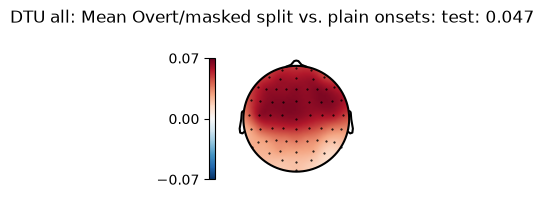

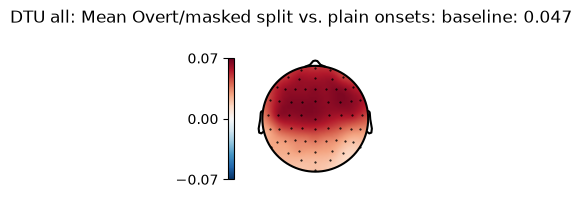

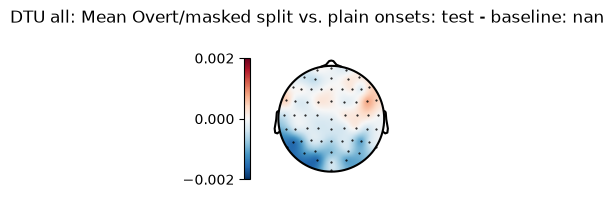

In [3]:
# Overt/masked split vs. plain onsets (DTU all)
# overt/masked = the split of each speaker's onsets into the part still visible in the mixture and
# the part the other speaker covers, with the speaker at its level in the mixture.
# Brodbeck et al. 2020 ran this comparison too: splitting onsets into overt/masked significantly improved the model overall, t = 6.81, p < .001.

# FULL_INMIX  = Eatt + Oatt + Eign + Oign + Emix + Omix   (Oatt, Oign at their level in the mixture)
# FULL_MASKED = Eatt + Oatt_overt + Oatt_masked + Eign + Oign_overt + Oign_masked + Emix + Omix
#
# Comparison: FULL_MASKED > FULL_INMIX
#   (does splitting Oatt/Oign into overt + masked improve the fit? overt + masked == Oatt/Oign,
#   so the two models carry the same onsets, only split or not)
#
# Full predictor names: print(FULL_MASKED) and print(FULL_INMIX); <recipe> is SPLIT_RECIPE
# (parameters.py), e.g. gammatone-<recipe>-on-overt-8 for the attended overt onsets.

data, diff, result = dtu_model_test('Overt/masked split vs. plain onsets', 'all', 'overt-masked')
show_topomap_trio(data, diff, result, 'Overt/masked split vs. plain onsets', 'DTU all', None)

In [4]:
display(result)
print(f"Overt/masked split vs. plain onsets (DTU all): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Overt/masked split vs. plain onsets (DTU all): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=18), tail=1, samples=10000, tfce=True, p = .142>

Overt/masked split vs. plain onsets (DTU all): TFCE t_max = 2.46, p = 0.142
Overt/masked split vs. plain onsets (DTU all): ROI model comparison t(17) = -0.093, p = 0.5363


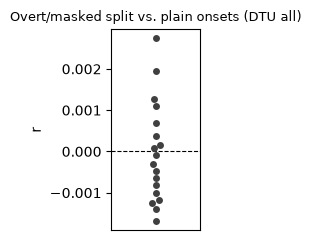

In [5]:
p = show_subject_swarm(diff, 'Overt/masked split vs. plain onsets', 'DTU all')

In [6]:
# Loaded once here, reused by every STRF/peak/waveform/attention-
# effect/masking-comparison cell in both this subsection and "masked
# onset" below - same reasoning as data_full above, for FULL_MASKED.
data_masked = dtu_trfs('all', 'overt-masked')

<small>

**Brodbeck et al. 2020: Two talkers, overt onset attend unique contribution**

- Overt attended onsets: t_max = 3.34, p = 0.027 (weaker than masked)

</small>

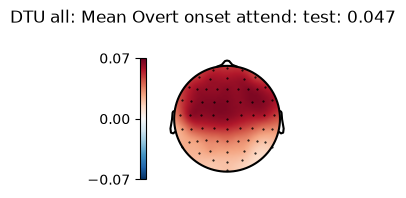

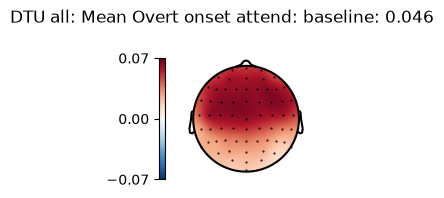

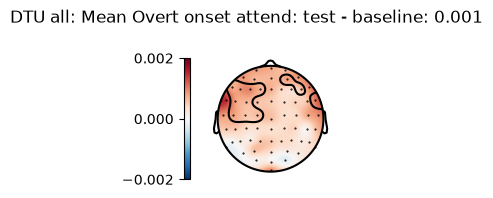

In [7]:
# Overt onset attend unique contribution (DTU all)
# Brodbeck et al. 2020 ran this comparison too: attended overt onsets unique contribution, t = 3.34, p = .027.
data, diff, result = dtu_model_test('Overt onset attend', 'all', 'overt-masked')
show_topomap_trio(data, diff, result, 'Overt onset attend', 'DTU all', None)

In [8]:
display(result)
print(f"Overt onset attend (DTU all): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Overt onset attend (DTU all): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=18), tail=1, samples=10000, tfce=True, p = .004>

Overt onset attend (DTU all): TFCE t_max = 2.85, p = 0.004
Overt onset attend (DTU all): ROI model comparison t(17) = 2.658, p = 0.0083


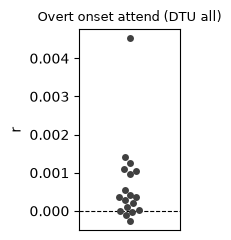

In [9]:
p = show_subject_swarm(diff, 'Overt onset attend', 'DTU all')

<small>

**Brodbeck et al. 2020: Two talkers, overt onset ignore unique contribution**

- Overt ignored onsets: t_max = 3.82, p = 0.016 (weaker than masked)

</small>

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


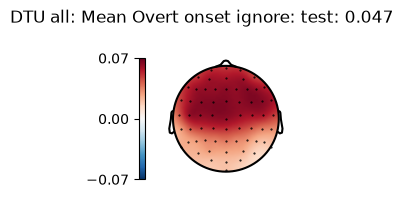

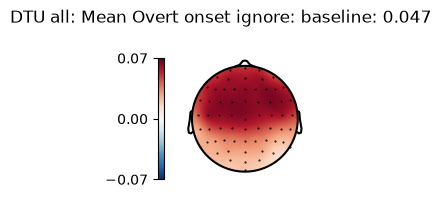

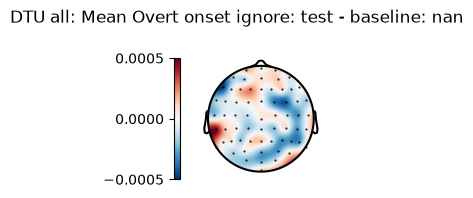

In [10]:
# Overt onset ignore unique contribution (DTU all)
# Brodbeck et al. 2020 ran this comparison too: ignored overt onsets unique contribution, t = 3.82, p = .016.
data, diff, result = dtu_model_test('Overt onset ignore', 'all', 'overt-masked')
show_topomap_trio(data, diff, result, 'Overt onset ignore', 'DTU all', None)

In [11]:
display(result)
print(f"Overt onset ignore (DTU all): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Overt onset ignore (DTU all): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=18), tail=1, samples=10000, tfce=True, p = .663>

Overt onset ignore (DTU all): TFCE t_max = 1.37, p = 0.663
Overt onset ignore (DTU all): ROI model comparison t(17) = -0.818, p = 0.7876


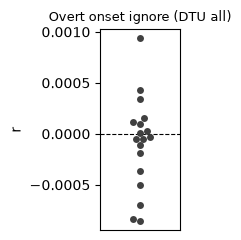

In [12]:
p = show_subject_swarm(diff, 'Overt onset ignore', 'DTU all')

<small>

**Brodbeck et al. 2020: Two talkers, overt onset STRFs**

- Same positive-then-negative shape
- Early positive peak: not changed by attention (may even look bigger for ignored, because the attended negative peak starts early and overlaps it)
- Only the negative peak is changed by attention (attended only)

</small>

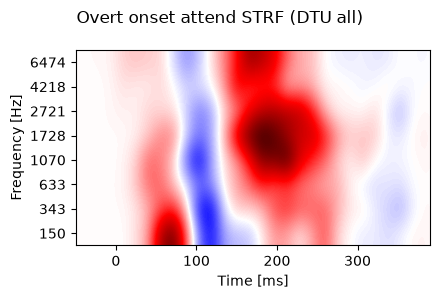

In [13]:
# Overt onset attend STRF (DTU all)
strf = extract_strf(data_masked, f'{SPLIT_COLUMN}_on_overt_8')
p = plot.Array(strf * 1e3, title='Overt onset attend STRF (DTU all)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

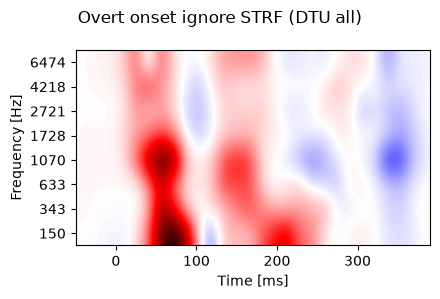

In [14]:
# Overt onset ignore STRF (DTU all)
strf = extract_strf(data_masked, f'bg_{SPLIT_COLUMN}_on_overt_8')
p = plot.Array(strf * 1e3, title='Overt onset ignore STRF (DTU all)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

<small>

**Brodbeck et al. 2020: Two talkers, overt onset peak latencies**

- Positive peak: attended 72 ms, ignored 83 ms (mixture 72 ms)
- Negative peak: attended 133 ms (mixture 138 ms)
- Peak search window: 20 to 250 ms for the overt/masked analysis (this notebook: the same)

</small>

In [15]:
# Overt onset attend peak amplitude & timing (DTU all)
data = extract_trf(data_masked, f'{SPLIT_COLUMN}_on_overt_8')
data = add_anchored_peak(data, 'positive', MASKED_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', MASKED_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Overt onset attend (DTU all) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Overt onset attend (DTU all) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Overt onset attend (DTU all) positive peak: 194 ms, amp 0.003885
Overt onset attend (DTU all) negative peak: 106 ms, amp -0.001759


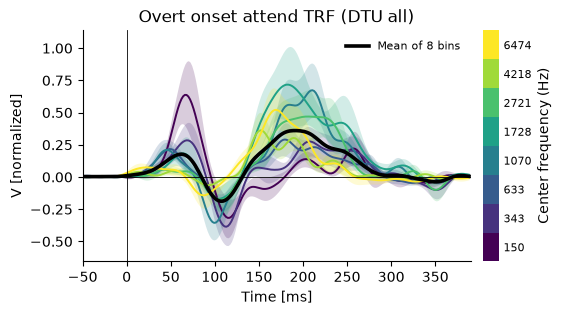

In [16]:
# Overt onset attend TRF per frequency bin (DTU all)
p = plot_trf_bins(data_masked, f'{SPLIT_COLUMN}_on_overt_8', 'Overt onset attend TRF (DTU all)')

In [17]:
# Overt onset ignore peak amplitude & timing (DTU all)
data = extract_trf(data_masked, f'bg_{SPLIT_COLUMN}_on_overt_8')
data = add_anchored_peak(data, 'positive', MASKED_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', MASKED_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Overt onset ignore (DTU all) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Overt onset ignore (DTU all) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Overt onset ignore (DTU all) positive peak: 62 ms, amp 0.002374
Overt onset ignore (DTU all) negative peak: 106 ms, amp -0.00028


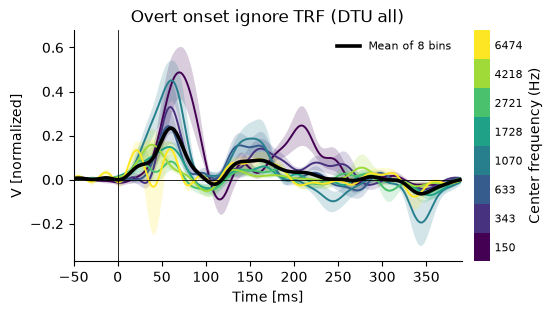

In [18]:
# Overt onset ignore TRF per frequency bin (DTU all)
p = plot_trf_bins(data_masked, f'bg_{SPLIT_COLUMN}_on_overt_8', 'Overt onset ignore TRF (DTU all)')

In [19]:
# Overt onset peak comparison across attend and ignore (DTU all)
dss = []
for role_name, column in (('attend', f'{SPLIT_COLUMN}_on_overt_8'), ('ignore', f'bg_{SPLIT_COLUMN}_on_overt_8')):
    ds = extract_trf(data_masked, column)
    ds[:, 'role'] = role_name
    dss.append(ds)
data = combine(dss)
data = add_anchored_peak(data, 'positive', MASKED_POSITIVE_PEAK_WINDOW, kind='max', by='role')
data = add_anchored_peak(data, 'negative', MASKED_NEGATIVE_PEAK_WINDOW, kind='min', by='role')

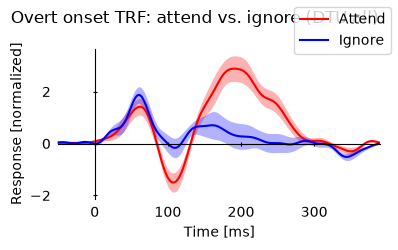

In [20]:
# The overt onset TRF waveform attend/ignore were each just measured
# from, overlaid so their shape and relative timing are visible
# directly, not just as extracted peak numbers below.
p = plot.UTSStat('trf_sm*1e3', 'role', data=data, match='subject', within_subject_error=True, frame='t', h=2.5, w=4, xlim=PLOT_WINDOW,
                  title='Overt onset TRF: attend vs. ignore (DTU all)', labels={'attend': 'Attend', 'ignore': 'Ignore'}, colors={'attend': 'red', 'ignore': 'blue'})

In [21]:
print_peak_table(data, 'positive', 'role')
print_peak_table(data, 'negative', 'role')


positive peak
subject   role         time (ms)           amp
S1        attend             197      0.001941
S2        attend             187      0.006166
S3        attend             209     0.0008985
S4        attend             168       0.00457
S5        attend             214      0.003225
S6        attend             214      0.001284
S7        attend             199      0.009019
S8        attend             183       0.01105
S9        attend             168      0.005005
S10       attend             177      0.001614
S11       attend             189     0.0007666
S12       attend             197      0.005115
S13       attend             214     0.0008842
S14       attend             209      0.008107
S15       attend             187      0.002584
S16       attend             183      0.001123
S17       attend             183      0.002415
S18       attend             209      0.004166
S1        ignore              64      0.003208
S2        ignore              56      0.00500

In [22]:
display(test.pairwise('positive_time', 'role', match='subject', data=data, corr=False, title='overt onset positive peak latency: attend vs. ignore'))
display(test.pairwise('negative_time', 'role', match='subject', data=data, corr=False, title='overt onset negative peak latency: attend vs. ignore'))

,ignore
attend,t17 = 34.99*** p < .001


,ignore
attend,t17 = -0.21 p = .839


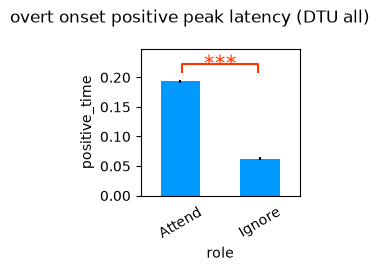

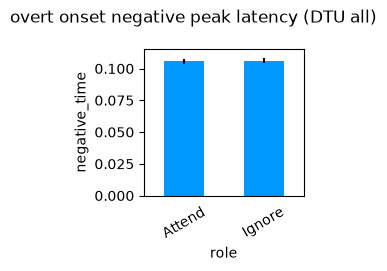

In [23]:
p = plot.Barplot('positive_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='overt onset positive peak latency (DTU all)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='overt onset negative peak latency (DTU all)')
p.set_xtick_rotation(30)

In [24]:
display(test.pairwise('positive_amp', 'role', match='subject', data=data, corr=False, title='overt onset positive peak amplitude: attend vs. ignore'))
display(test.pairwise('negative_amp', 'role', match='subject', data=data, corr=False, title='overt onset negative peak amplitude: attend vs. ignore'))

,ignore
attend,t17 = 1.90 p = .074


,ignore
attend,t17 = -2.65* p = .017


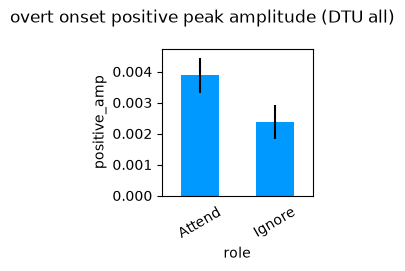

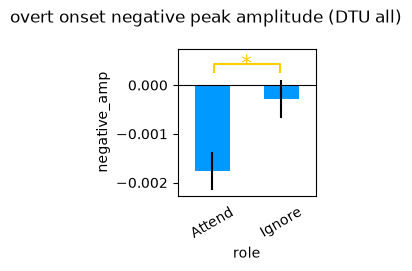

In [25]:
p = plot.Barplot('positive_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='overt onset positive peak amplitude (DTU all)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='overt onset negative peak amplitude (DTU all)')
p.set_xtick_rotation(30)

<small>

**Brodbeck et al. 2020: Two talkers, overt onset attention effect**

- No attention effect on the early positive peak
- Attention effect on the later negative peak, starting near the top of the positive peak

</small>

Permutation test:   0%|          | 0/10000 [00:00<?, ? permutations/s]

Overt onset attention effect: attend - ignore (DTU all): bins that differ from 0 somewhere: 1728 Hz


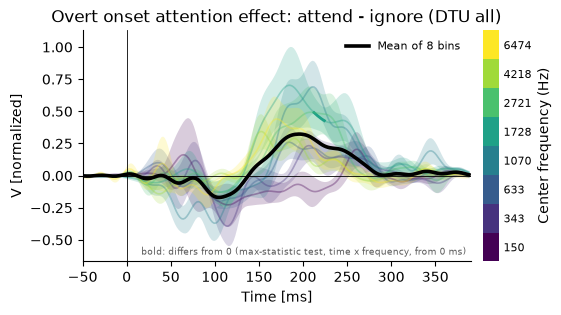

In [26]:
# Overt onset attention effect: attend - ignore (DTU all)
p = plot_trf_bins(data_masked, f'{SPLIT_COLUMN}_on_overt_8', 'Overt onset attention effect: attend - ignore (DTU all)', subtract=f'bg_{SPLIT_COLUMN}_on_overt_8')

Permutation test:   0%|          | 0/10000 [00:00<?, ? permutations/s]

Overt onset attention effect: attend - ignore (DTU all): differs from 0 (max-statistic permutation test from 0 ms, two-tailed; ranges < 10 ms apart joined) at 181-228 ms (p = 0.023)


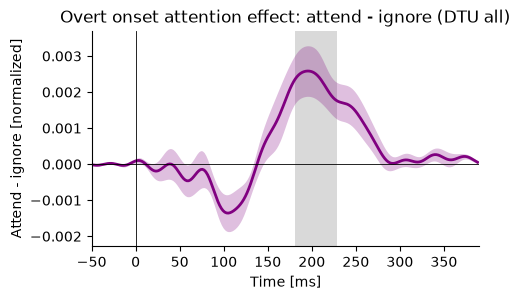

In [27]:
# The same attention effect as one waveform: summed over the frequency bins, mean +- 1 SEM across
# subjects; grey where attend - ignore differs from 0 (TFCE over time, two-tailed).
p = plot_attention_effect(data_masked, f'{SPLIT_COLUMN}_on_overt_8', f'bg_{SPLIT_COLUMN}_on_overt_8', 'Overt onset attention effect: attend - ignore (DTU all)')

## DTU all (masked onset)

<small>

**Brodbeck et al. 2020: Two talkers, masked onset attend unique contribution**

- Masked attended onsets: t_max = 8.42, p < 0.001

</small>

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


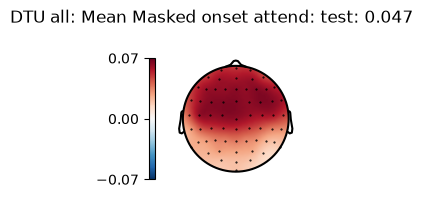

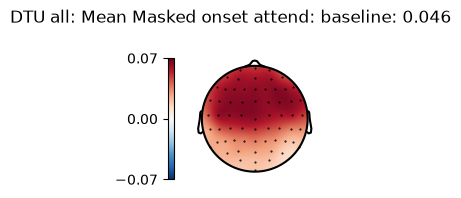

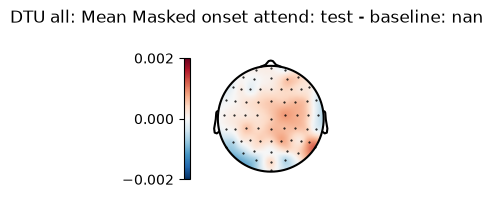

In [28]:
# Masked onset attend unique contribution (DTU all)
# Brodbeck et al. 2020 ran this comparison too: attended masked onsets unique contribution, t = 8.42, p < .001 - the strongest of the four masking predictors.
data, diff, result = dtu_model_test('Masked onset attend', 'all', 'overt-masked')
show_topomap_trio(data, diff, result, 'Masked onset attend', 'DTU all', None)

In [29]:
display(result)
print(f"Masked onset attend (DTU all): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Masked onset attend (DTU all): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=18), tail=1, samples=10000, tfce=True, p = .071>

Masked onset attend (DTU all): TFCE t_max = 2.68, p = 0.071
Masked onset attend (DTU all): ROI model comparison t(17) = 1.489, p = 0.0774


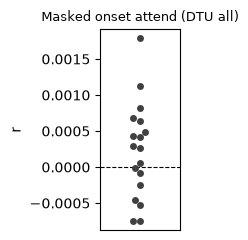

In [30]:
p = show_subject_swarm(diff, 'Masked onset attend', 'DTU all')

<small>

**Brodbeck et al. 2020: Two talkers, masked onset ignore unique contribution**

- Masked ignored onsets: t_max = 5.23, p < 0.001
- Key finding: the brain recovers masked onsets even for the ignored speaker

</small>

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


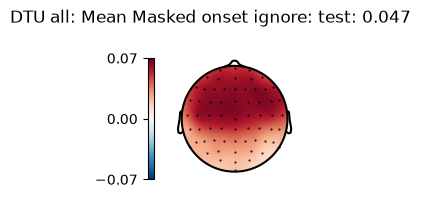

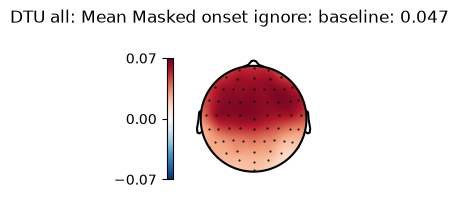

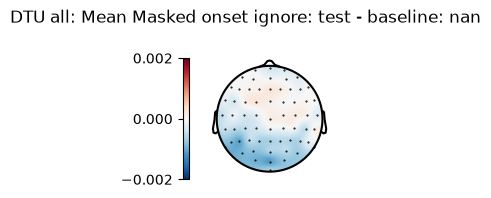

In [31]:
# Masked onset ignore unique contribution (DTU all)
# Brodbeck et al. 2020 ran this comparison too: ignored masked onsets unique contribution, t = 5.23, p < .001 - the brain recovers masked information even for the ignored speaker.
data, diff, result = dtu_model_test('Masked onset ignore', 'all', 'overt-masked')
show_topomap_trio(data, diff, result, 'Masked onset ignore', 'DTU all', None)

In [32]:
display(result)
print(f"Masked onset ignore (DTU all): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Masked onset ignore (DTU all): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=18), tail=1, samples=10000, tfce=True, p = .869>

Masked onset ignore (DTU all): TFCE t_max = 0.83, p = 0.869
Masked onset ignore (DTU all): ROI model comparison t(17) = -0.384, p = 0.6470


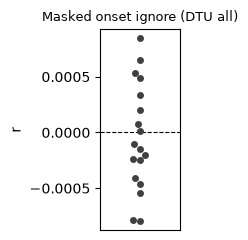

In [33]:
p = show_subject_swarm(diff, 'Masked onset ignore', 'DTU all')

<small>

**Brodbeck et al. 2020: Two talkers, masked onset STRFs**

- Same positive-then-negative shape, but later than overt onsets
- Even the early positive peak is bigger for the attended speaker (an early attention effect)

</small>

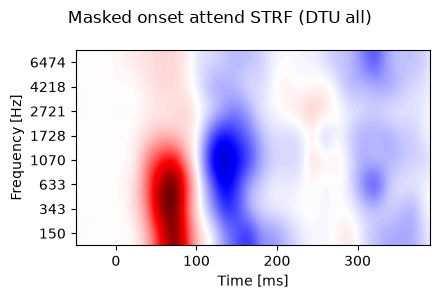

In [34]:
# Masked onset attend STRF (DTU all)
strf = extract_strf(data_masked, f'{SPLIT_COLUMN}_on_masked_8')
p = plot.Array(strf * 1e3, title='Masked onset attend STRF (DTU all)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

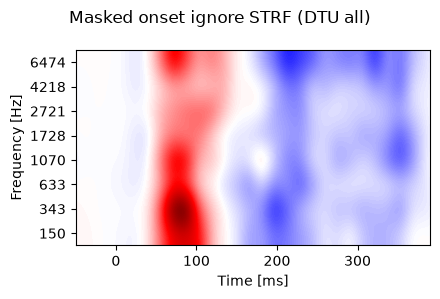

In [35]:
# Masked onset ignore STRF (DTU all)
strf = extract_strf(data_masked, f'bg_{SPLIT_COLUMN}_on_masked_8')
p = plot.Array(strf * 1e3, title='Masked onset ignore STRF (DTU all)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

<small>

**Brodbeck et al. 2020: Two talkers, masked onset peak latencies**

- Positive peak: attended 91 ms, ignored 97 ms
- Negative peak: attended 182 ms
- Masked onsets lag overt onsets by at least 15 ms at each peak (about 20 ms on average)
- Peak search window: 20 to 250 ms (this notebook: the same)

</small>

In [36]:
# Masked onset attend peak amplitude & timing (DTU all)
data = extract_trf(data_masked, f'{SPLIT_COLUMN}_on_masked_8')
data = add_anchored_peak(data, 'positive', MASKED_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', MASKED_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Masked onset attend (DTU all) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Masked onset attend (DTU all) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Masked onset attend (DTU all) positive peak: 69 ms, amp 0.002262
Masked onset attend (DTU all) negative peak: 143 ms, amp -0.001851


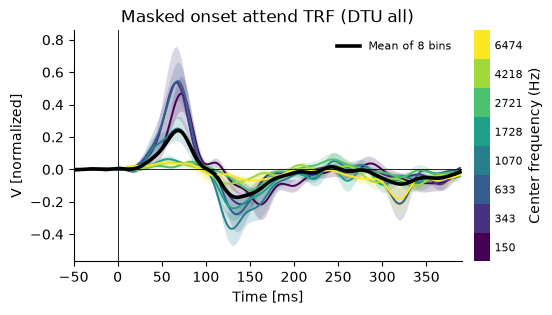

In [37]:
# Masked onset attend TRF per frequency bin (DTU all)
p = plot_trf_bins(data_masked, f'{SPLIT_COLUMN}_on_masked_8', 'Masked onset attend TRF (DTU all)')

In [38]:
# Masked onset ignore peak amplitude & timing (DTU all)
data = extract_trf(data_masked, f'bg_{SPLIT_COLUMN}_on_masked_8')
data = add_anchored_peak(data, 'positive', MASKED_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', MASKED_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Masked onset ignore (DTU all) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Masked onset ignore (DTU all) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Masked onset ignore (DTU all) positive peak: 78 ms, amp 0.001657
Masked onset ignore (DTU all) negative peak: 219 ms, amp -0.001185


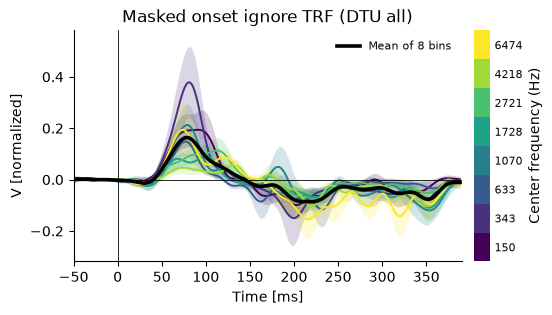

In [39]:
# Masked onset ignore TRF per frequency bin (DTU all)
p = plot_trf_bins(data_masked, f'bg_{SPLIT_COLUMN}_on_masked_8', 'Masked onset ignore TRF (DTU all)')

In [40]:
# Masked onset peak comparison across attend and ignore (DTU all)
dss = []
for role_name, column in (('attend', f'{SPLIT_COLUMN}_on_masked_8'), ('ignore', f'bg_{SPLIT_COLUMN}_on_masked_8')):
    ds = extract_trf(data_masked, column)
    ds[:, 'role'] = role_name
    dss.append(ds)
data = combine(dss)
data = add_anchored_peak(data, 'positive', MASKED_POSITIVE_PEAK_WINDOW, kind='max', by='role')
data = add_anchored_peak(data, 'negative', MASKED_NEGATIVE_PEAK_WINDOW, kind='min', by='role')

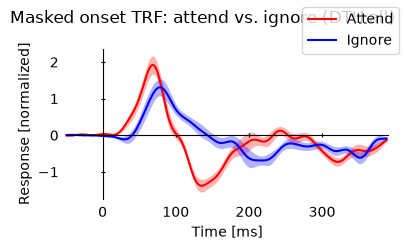

In [41]:
# The masked onset TRF waveform attend/ignore were each just measured
# from, overlaid so their shape and relative timing are visible
# directly, not just as extracted peak numbers below.
p = plot.UTSStat('trf_sm*1e3', 'role', data=data, match='subject', within_subject_error=True, frame='t', h=2.5, w=4, xlim=PLOT_WINDOW,
                  title='Masked onset TRF: attend vs. ignore (DTU all)', labels={'attend': 'Attend', 'ignore': 'Ignore'}, colors={'attend': 'red', 'ignore': 'blue'})

In [42]:
print_peak_table(data, 'positive', 'role')
print_peak_table(data, 'negative', 'role')


positive peak
subject   role         time (ms)           amp
S1        attend              70      0.003323
S2        attend              66       0.00534
S3        attend              84      0.002215
S4        attend              72      0.001625
S5        attend              68       0.00347
S6        attend              91     0.0004437
S7        attend              80     6.251e-05
S8        attend              70       0.00171
S9        attend              66      0.001532
S10       attend              60      0.004525
S11       attend              66      0.001896
S12       attend              45      0.003813
S13       attend              76      0.003466
S14       attend              72      0.001642
S15       attend              68      0.002276
S16       attend              72      0.001794
S17       attend              62     0.0005955
S18       attend              58      0.000986
S1        ignore              78      0.002828
S2        ignore              76      0.00175

In [43]:
display(test.pairwise('positive_time', 'role', match='subject', data=data, corr=False, title='masked onset positive peak latency: attend vs. ignore'))
display(test.pairwise('negative_time', 'role', match='subject', data=data, corr=False, title='masked onset negative peak latency: attend vs. ignore'))

,ignore
attend,t17 = -2.35* p = .031


,ignore
attend,t17 = -18.00*** p < .001


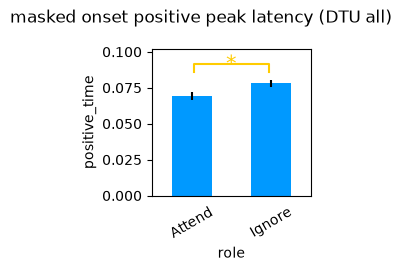

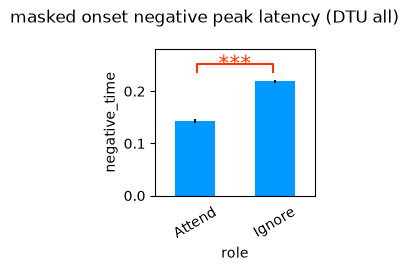

In [44]:
p = plot.Barplot('positive_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='masked onset positive peak latency (DTU all)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='masked onset negative peak latency (DTU all)')
p.set_xtick_rotation(30)

In [45]:
display(test.pairwise('positive_amp', 'role', match='subject', data=data, corr=False, title='masked onset positive peak amplitude: attend vs. ignore'))
display(test.pairwise('negative_amp', 'role', match='subject', data=data, corr=False, title='masked onset negative peak amplitude: attend vs. ignore'))

,ignore
attend,t17 = 1.34 p = .198


,ignore
attend,t17 = -1.95 p = .068


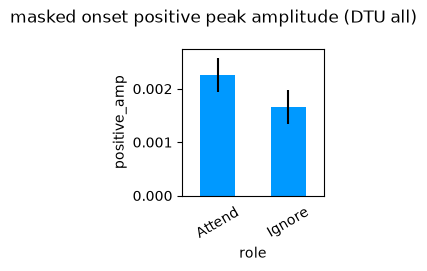

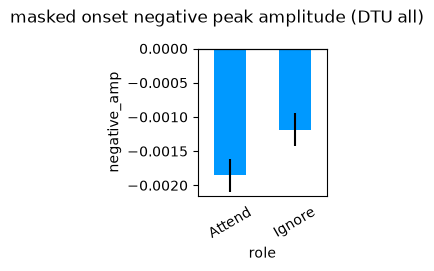

In [46]:
p = plot.Barplot('positive_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='masked onset positive peak amplitude (DTU all)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='masked onset negative peak amplitude (DTU all)')
p.set_xtick_rotation(30)

<small>

**Brodbeck et al. 2020: Two talkers, masked onset attention effect**

- Early positive peak bigger for attended than ignored, despite the following negative peak

</small>

Permutation test:   0%|          | 0/10000 [00:00<?, ? permutations/s]

Masked onset attention effect: attend - ignore (DTU all): bins that differ from 0 somewhere: 1070 Hz, 1728 Hz, 2721 Hz


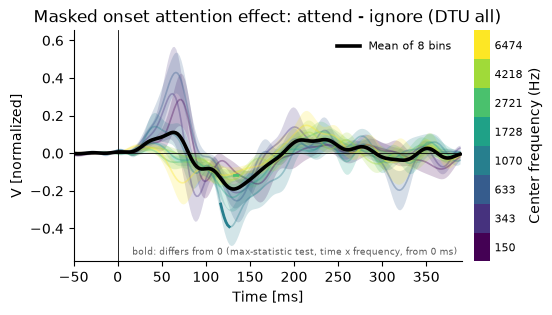

In [47]:
# Masked onset attention effect: attend - ignore (DTU all)
p = plot_trf_bins(data_masked, f'{SPLIT_COLUMN}_on_masked_8', 'Masked onset attention effect: attend - ignore (DTU all)', subtract=f'bg_{SPLIT_COLUMN}_on_masked_8')

Permutation test:   0%|          | 0/10000 [00:00<?, ? permutations/s]

Masked onset attention effect: attend - ignore (DTU all): differs from 0 (max-statistic permutation test from 0 ms, two-tailed; ranges < 10 ms apart joined) at 105-160 ms (p < 0.001)


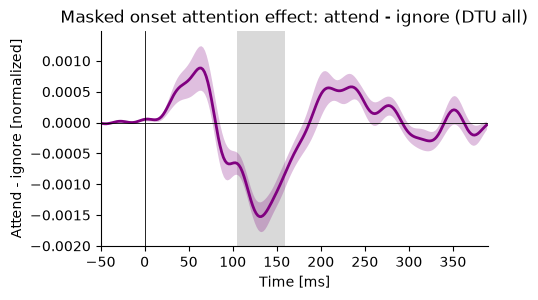

In [48]:
# The same attention effect as one waveform: summed over the frequency bins, mean +- 1 SEM across
# subjects; grey where attend - ignore differs from 0 (TFCE over time, two-tailed).
p = plot_attention_effect(data_masked, f'{SPLIT_COLUMN}_on_masked_8', f'bg_{SPLIT_COLUMN}_on_masked_8', 'Masked onset attention effect: attend - ignore (DTU all)')

<small>

**Brodbeck et al. 2020: Two talkers, overt vs masked peaks, attended**

- Positive peak later for masked: 91 vs 72 ms, t(25) = 2.85, p = 0.009
- Negative peak later for masked: 182 vs 133 ms, t(25) = 4.45, p < 0.001

</small>

In [49]:
# Overt vs. masked peak comparison, attend (DTU all)
# Brodbeck et al. 2020 ran this comparison too: attended overt 72ms vs. attended masked 91ms (t=2.85,p=.009); combined (not stream-split) late negative peak, overt 133ms vs. masked 182ms (t=4.45,p<.001).
dss = []
for masking, column in (('overt', f'{SPLIT_COLUMN}_on_overt_8'), ('masked', f'{SPLIT_COLUMN}_on_masked_8')):
    ds = extract_trf(data_masked, column)
    ds[:, 'masking'] = masking
    dss.append(ds)
data = combine(dss)
data = add_anchored_peak(data, 'positive', MASKED_POSITIVE_PEAK_WINDOW, kind='max', by='masking')
data = add_anchored_peak(data, 'negative', MASKED_NEGATIVE_PEAK_WINDOW, kind='min', by='masking')

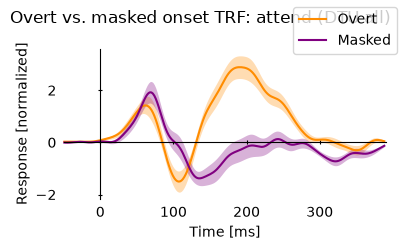

In [50]:
# Overt and masked onset TRFs of the attended speaker, overlaid
p = plot.UTSStat('trf_sm*1e3', 'masking', data=data, match='subject', within_subject_error=True, frame='t', h=2.5, w=4, xlim=PLOT_WINDOW,
                  title='Overt vs. masked onset TRF: attend (DTU all)', labels=LABELS_MASKING, colors=COLORS_MASKING)

In [51]:
print_peak_table(data, 'positive', 'masking')
print_peak_table(data, 'negative', 'masking')


positive peak
subject   masking      time (ms)           amp
S1        overt              197      0.001941
S2        overt              187      0.006166
S3        overt              209     0.0008985
S4        overt              168       0.00457
S5        overt              214      0.003225
S6        overt              214      0.001284
S7        overt              199      0.009019
S8        overt              183       0.01105
S9        overt              168      0.005005
S10       overt              177      0.001614
S11       overt              189     0.0007666
S12       overt              197      0.005115
S13       overt              214     0.0008842
S14       overt              209      0.008107
S15       overt              187      0.002584
S16       overt              183      0.001123
S17       overt              183      0.002415
S18       overt              209      0.004166
S1        masked              70      0.003323
S2        masked              66       0.0053

In [52]:
display(test.pairwise('positive_time', 'masking', match='subject', data=data, corr=False, title='attend positive peak latency: overt vs. masked'))
display(test.pairwise('negative_time', 'masking', match='subject', data=data, corr=False, title='attend negative peak latency: overt vs. masked'))

,masked
overt,t17 = 34.12*** p < .001


,masked
overt,t17 = -10.62*** p < .001


In [53]:
display(test.pairwise('positive_amp', 'masking', match='subject', data=data, corr=False, title='attend positive peak amplitude: overt vs. masked'))
display(test.pairwise('negative_amp', 'masking', match='subject', data=data, corr=False, title='attend negative peak amplitude: overt vs. masked'))

,masked
overt,t17 = 1.92 p = .072


,masked
overt,t17 = 0.16 p = .873


<small>

**Brodbeck et al. 2020: Two talkers, overt vs masked peaks, ignored**

- Positive peak later for masked: 97 vs 83 ms, t(25) = 6.11, p < 0.001

</small>

In [54]:
# Overt vs. masked peak comparison, ignore (DTU all)
# Brodbeck et al. 2020 ran this comparison too: ignored overt 83ms vs. ignored masked 97ms (t=6.11,p<.001); combined (not stream-split) late negative peak, overt 133ms vs. masked 182ms (t=4.45,p<.001).
dss = []
for masking, column in (('overt', f'bg_{SPLIT_COLUMN}_on_overt_8'), ('masked', f'bg_{SPLIT_COLUMN}_on_masked_8')):
    ds = extract_trf(data_masked, column)
    ds[:, 'masking'] = masking
    dss.append(ds)
data = combine(dss)
data = add_anchored_peak(data, 'positive', MASKED_POSITIVE_PEAK_WINDOW, kind='max', by='masking')
data = add_anchored_peak(data, 'negative', MASKED_NEGATIVE_PEAK_WINDOW, kind='min', by='masking')

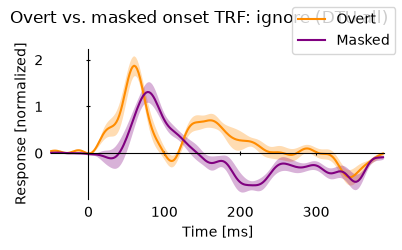

In [55]:
# Overt and masked onset TRFs of the ignored speaker, overlaid
p = plot.UTSStat('trf_sm*1e3', 'masking', data=data, match='subject', within_subject_error=True, frame='t', h=2.5, w=4, xlim=PLOT_WINDOW,
                  title='Overt vs. masked onset TRF: ignore (DTU all)', labels=LABELS_MASKING, colors=COLORS_MASKING)

In [56]:
print_peak_table(data, 'positive', 'masking')
print_peak_table(data, 'negative', 'masking')


positive peak
subject   masking      time (ms)           amp
S1        overt               64      0.003208
S2        overt               56      0.005005
S3        overt               82      0.001371
S4        overt               74      0.003847
S5        overt               74       0.00124
S6        overt               62      0.001933
S7        overt               64      0.001004
S8        overt               54      0.001762
S9        overt               48     0.0008006
S10       overt               58      0.000981
S11       overt               54      0.002603
S12       overt               52      0.002678
S13       overt               62      0.001867
S14       overt               68      0.003189
S15       overt               43      0.005016
S16       overt               56      0.003901
S17       overt               84     0.0002059
S18       overt               66      0.002128
S1        masked              78      0.002828
S2        masked              76      0.00175

In [57]:
display(test.pairwise('positive_time', 'masking', match='subject', data=data, corr=False, title='ignore positive peak latency: overt vs. masked'))
display(test.pairwise('negative_time', 'masking', match='subject', data=data, corr=False, title='ignore negative peak latency: overt vs. masked'))

,masked
overt,t17 = -4.61*** p < .001


,masked
overt,t17 = -21.06*** p < .001


In [58]:
display(test.pairwise('positive_amp', 'masking', match='subject', data=data, corr=False, title='ignore positive peak amplitude: overt vs. masked'))
display(test.pairwise('negative_amp', 'masking', match='subject', data=data, corr=False, title='ignore negative peak amplitude: overt vs. masked'))

,masked
overt,t17 = 1.62 p = .124


,masked
overt,t17 = 3.08** p = .007


<small>

**Brodbeck et al. 2020: Two talkers, stream x masking interaction**

- ANOVA on positive peak amplitude (attended/ignored x overt/masked): F(1,25) = 24.45, p < 0.001
- Overt onsets: no early attention effect; masked onsets: early attention effect

</small>

In [59]:
# Stream x masking interaction on peak amplitude (DTU all)
# Brodbeck et al. 2020 ran this comparison too: stream x masking interaction, F(1,25) = 24.45, p < .001 - overt onsets show no early attention effect, masked onsets do.
dss = []
for stream_name, is_attend in (('attend', True), ('ignore', False)):
    for masking_name in ('overt', 'masked'):
        prefix = '' if is_attend else 'bg_'
        column = f'{prefix}{SPLIT_COLUMN}_on_{masking_name}_8'
        ds = extract_trf(data_masked, column)
        ds[:, 'stream'] = stream_name
        ds[:, 'masking'] = masking_name
        dss.append(ds)
data = combine(dss)
data = add_anchored_peak(data, 'positive', MASKED_POSITIVE_PEAK_WINDOW, kind='max', by=('stream', 'masking'))
display(test.ANOVA('positive_amp', 'stream * masking * subject', data=data, title='stream x masking interaction (DTU all)'))

<ANOVA: positive_amp ~ stream + masking + stream x masking + subject + stream x subject + masking x subject + stream x masking x subject
  
  stream x masking interaction (DTU all)
  
                       SS   df     MS   MS(denom)   df(denom)         F      p
  ----------------------------------------------------------------------------
  stream             0.00    1   0.00        0.00          17   9.90**    .006
  masking            0.00    1   0.00        0.00          17   8.91**    .008
  stream x masking   0.00    1   0.00        0.00          17   0.68      .422
  ----------------------------------------------------------------------------
  Total              0.00   71
>

## DTU all (intensity-level control)

### Overt and masked onsets together

Overt and masked onsets are made from the same syllable starts, so they rise and fall together. Removed one at a time (the tests above), each can stand in for the other, and both can look useless even when the speaker's onsets matter. Here both are removed at once: if the speaker's onsets add predictive power, this joint test should show it, as the unsplit onset does (the reference tests below, the same onsets unsplit, at the speaker's level in the mixture).

- Joint test significant, one-at-a-time tests not: the information is there, but overt and masked cannot be told apart in these data.
- Joint test not significant either: the overt/masked predictors carry less than the unsplit onsets.

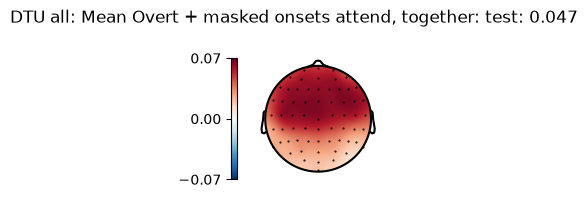

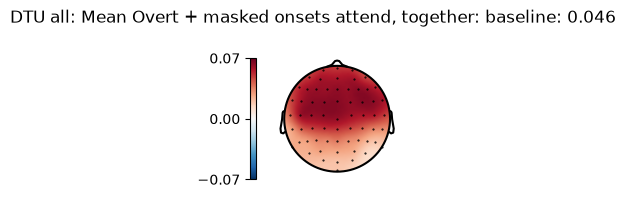

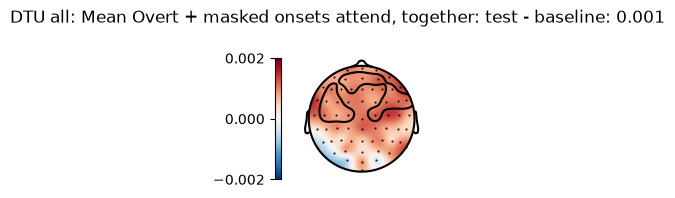

In [60]:
# Overt + masked onsets attend, together (DTU all)
# both of the attended speaker's onset predictors removed at once
data, diff, result = dtu_model_test('Overt + masked onsets attend, together', 'all', 'overt-masked')
show_topomap_trio(data, diff, result, 'Overt + masked onsets attend, together', 'DTU all', None)

In [61]:
display(result)
print(f"Overt + masked onsets attend, together (DTU all): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Overt + masked onsets attend, together (DTU all): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=18), tail=1, samples=10000, tfce=True, p = .003>

Overt + masked onsets attend, together (DTU all): TFCE t_max = 3.58, p = 0.003
Overt + masked onsets attend, together (DTU all): ROI model comparison t(17) = 3.168, p = 0.0028


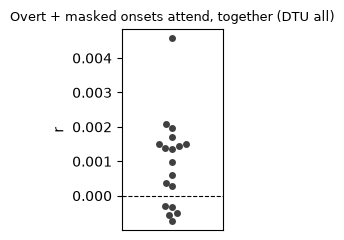

In [62]:
p = show_subject_swarm(diff, 'Overt + masked onsets attend, together', 'DTU all')

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


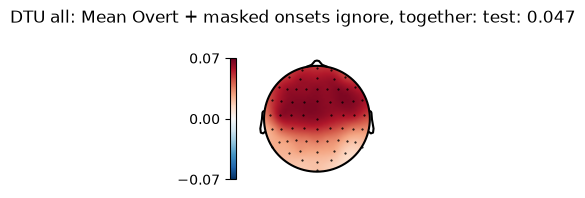

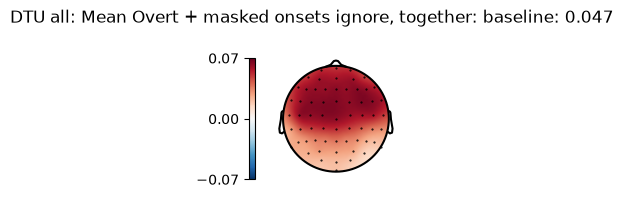

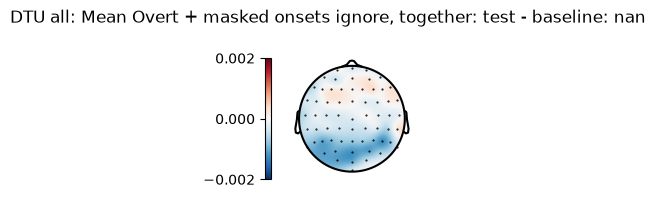

In [63]:
# Overt + masked onsets ignore, together (DTU all)
# both of the ignored speaker's onset predictors removed at once
data, diff, result = dtu_model_test('Overt + masked onsets ignore, together', 'all', 'overt-masked')
show_topomap_trio(data, diff, result, 'Overt + masked onsets ignore, together', 'DTU all', None)

In [64]:
display(result)
print(f"Overt + masked onsets ignore, together (DTU all): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Overt + masked onsets ignore, together (DTU all): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=18), tail=1, samples=10000, tfce=True, p = .649>

Overt + masked onsets ignore, together (DTU all): TFCE t_max = 1.12, p = 0.649
Overt + masked onsets ignore, together (DTU all): ROI model comparison t(17) = -0.306, p = 0.6185


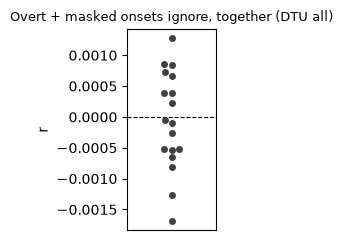

In [65]:
p = show_subject_swarm(diff, 'Overt + masked onsets ignore, together', 'DTU all')

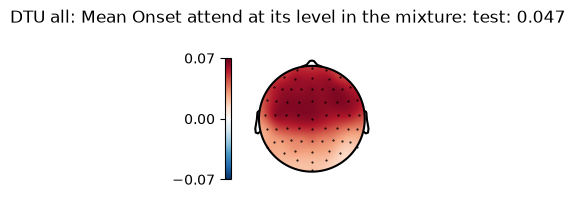

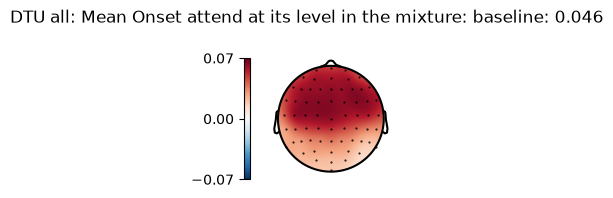

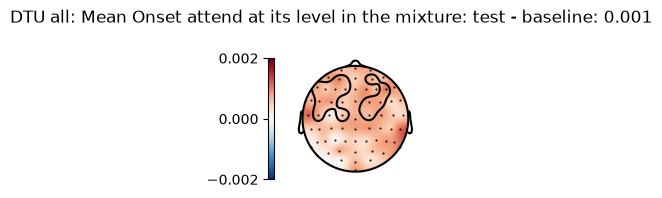

In [66]:
# Onset attend at its level in the mixture (DTU all)
# reference: the same onsets unsplit, removed from FULL_INMIX
data, diff, result = dtu_model_test('Onset attend at its level in the mixture', 'all', 'overt-masked')
show_topomap_trio(data, diff, result, 'Onset attend at its level in the mixture', 'DTU all', None)

In [67]:
display(result)
print(f"Onset attend at its level in the mixture (DTU all): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Onset attend at its level in the mixture (DTU all): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=18), tail=1, samples=10000, tfce=True, p < .001>

Onset attend at its level in the mixture (DTU all): TFCE t_max = 4.73, p < 0.001
Onset attend at its level in the mixture (DTU all): ROI model comparison t(17) = 4.133, p = 0.0003


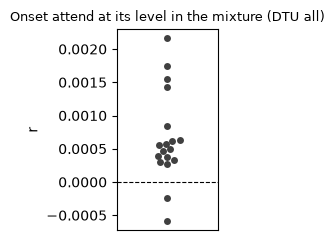

In [68]:
p = show_subject_swarm(diff, 'Onset attend at its level in the mixture', 'DTU all')

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


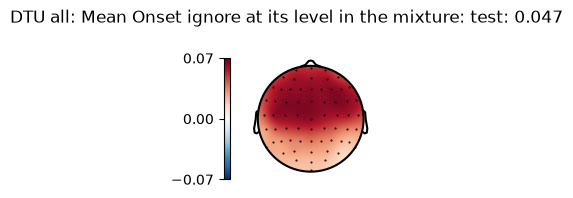

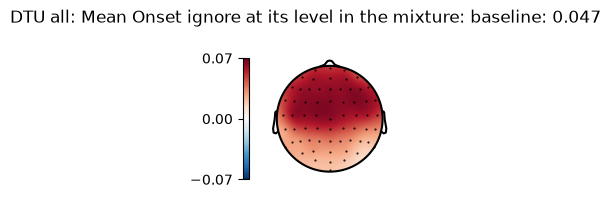

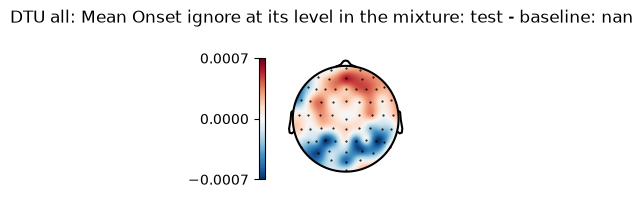

In [69]:
# Onset ignore at its level in the mixture (DTU all)
# reference: the same onsets unsplit, removed from FULL_INMIX
data, diff, result = dtu_model_test('Onset ignore at its level in the mixture', 'all', 'overt-masked')
show_topomap_trio(data, diff, result, 'Onset ignore at its level in the mixture', 'DTU all', None)

In [70]:
display(result)
print(f"Onset ignore at its level in the mixture (DTU all): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Onset ignore at its level in the mixture (DTU all): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=18), tail=1, samples=10000, tfce=True, p = .112>

Onset ignore at its level in the mixture (DTU all): TFCE t_max = 2.46, p = 0.112
Onset ignore at its level in the mixture (DTU all): ROI model comparison t(17) = 1.540, p = 0.0710


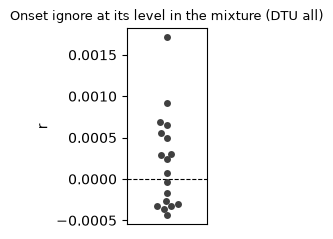

In [71]:
p = show_subject_swarm(diff, 'Onset ignore at its level in the mixture', 'DTU all')

<small>

**Brodbeck et al. 2020: Two talkers, masked-aware vs level-aware model**

- The model that knows about the ignored speaker beats the loudness-tier model: t_max = 9.21, p < 0.001
- So the masked-onset effect is not just a response to quieter onsets

</small>

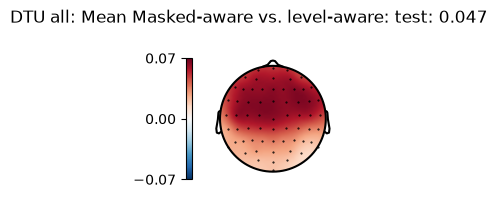

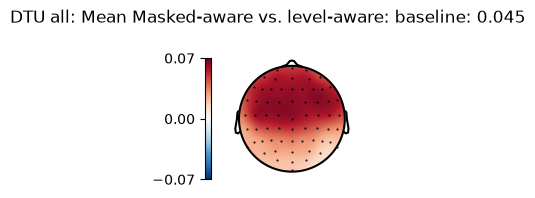

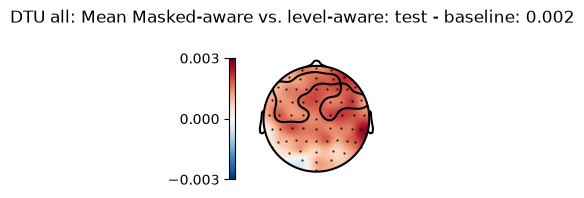

In [72]:
# Masked-aware vs. level-aware (DTU all)
# Brodbeck et al. 2020 ran this comparison too: the ignored-speaker-aware model still beat the loudness-only model, t = 9.21, p < .001 - the masking effect isn't just about volume.
data, diff, result = dtu_model_test('Masked-aware vs. level-aware', 'all', 'overt-masked')
show_topomap_trio(data, diff, result, 'Masked-aware vs. level-aware', 'DTU all', None)

In [73]:
display(result)
print(f"Masked-aware vs. level-aware (DTU all): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Masked-aware vs. level-aware (DTU all): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=18), tail=1, samples=10000, tfce=True, p < .001>

Masked-aware vs. level-aware (DTU all): TFCE t_max = 4.44, p < 0.001
Masked-aware vs. level-aware (DTU all): ROI model comparison t(17) = 3.938, p = 0.0005


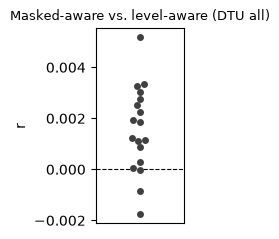

In [74]:
p = show_subject_swarm(diff, 'Masked-aware vs. level-aware', 'DTU all')